In [2]:
#Jeffrey Tam
#INST 414
#October 23, 2026
#Module 3

In [3]:
%matplotlib inline

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.sparse import lil_matrix

#Used to deal with memory leak warnings from sklearn lib
import warnings
warnings.simplefilter('ignore')

In [5]:
file_name = "openings.csv"

In [6]:
#Subset of original dataframe
file_name = "openings.csv"
df = pd.read_csv(file_name)
#Cleaning dataset
df = df.fillna(0)

#Note, Unnamed: 0 is the opening id
new_df = df[["Unnamed: 0", "Opening", "move1w", "move1b", "move2w", "move2b", "move3w", "move3b", "move4w", "move4b"]].copy()
new_df

,Unnamed: 0,Opening,move1w,move1b,move2w,move2b,move3w,move3b,move4w,move4b
0,0,"Alekhine Defense, Balogh Variation",e4,Nf6,e5,Nd5,d4,d6,Bc4,0
1,1,"Alekhine Defense, Brooklyn Variation",e4,Nf6,e5,Ng8,0,0,0,0
2,2,"Alekhine Defense, Exchange Variation",e4,Nf6,e5,Nd5,d4,d6,c4,Nb6
3,3,"Alekhine Defense, Four Pawns Attack",e4,Nf6,e5,Nd5,d4,d6,c4,Nb6
4,4,"Alekhine Defense, Four Pawns Attack, Fianchett...",e4,Nf6,e5,Nd5,d4,d6,c4,Nb6
...,...,...,...,...,...,...,...,...,...,...
1879,1879,"Zukertort Opening, Sicilian Invitation",Nf3,c5,0,0,0,0,0,0
1880,1880,"Zukertort Opening, Slav Invitation",Nf3,c6,0,0,0,0,0,0
1881,1881,"Zukertort Opening, Symmetrical Variation",Nf3,Nf6,0,0,0,0,0,0
1882,1882,"Zukertort Opening, Tennison Gambit",Nf3,d5,e4,0,0,0,0,0


In [7]:
#Mapping opening id to the opening name
list_opening_id = new_df["Unnamed: 0"].values.tolist()
list_opening_name = new_df["Opening"].values.tolist()


opening_to_id_map = dict(zip(list_opening_id, list_opening_name))
id_to_moves = {} #Used to id the moves, as a test, since every name is different, but switch it to ID for clearity/efficency 
move_id_to_moves = {} #Used to identify move sets in a map for matrix

for r in new_df.itertuples(index=False):
    #Used to clean up 1st move on white side, returns scientific notation instead of a string, i.e e3 = 00E+03
    move1w = r.move1w
    # if(r.move1w == "00E+03" or r.move1w == "00E+04"):
    #     print({r.Opening: [r.move1w, r.move1b, r.move2w, r.move2b, r.move3w, r.move3b, r.move4w, r.move4b]})
    if(move1w == "00E+03"):
        move1w = "e3"
    if(move1w == "00E+04"):
        move1w = "e4"
    id_to_moves.update({r._0: [move1w, r.move1b, r.move2w, r.move2b, r.move3w, r.move3b, r.move4w, r.move4b]})

# for k, v in id_to_moves.items():
#     print(k, " ", v)

In [8]:
#Columns for every move by opening from 8 columns
positions_set= set()
posit_names = ['move1w', 'move1b', 'move2w', 'move2b', 'move3w','move3b', 'move4w', 'move4b']
for name in posit_names:
    list_a = new_df[name].values.tolist()
    positions_set.update(list_a)

positions_set.discard(0)
positions_set.discard('00E+03')
positions_set.discard('00E+04')
#Num of features in the matrix
len(positions_set)

count = 0
#Convert set to a map
for x in positions_set:
    move_id_to_moves[x] = count
    count += 1

In [9]:
#Sparse matrix
matrix_sparse = lil_matrix((len(list_opening_name), len(positions_set)), dtype=bool)

for row, opening in enumerate(list_opening_name):
    for move in id_to_moves[row]:
        if(move != 0):
            this_index = move_id_to_moves[move]
            matrix_sparse[row, this_index] = 1


In [10]:
#new data frame 
df = pd.DataFrame.sparse.from_spmatrix(
    matrix_sparse,
    index=list_opening_name,
    columns=positions_set
)

df = df.astype(int)
df

,e4,d5,Qa4+,e5,b5,Na3,Ne7,Ne5,dxe5,Nxd5,...,Nxf7,Qf6,Ne2,d3,Qh4,Nxe5,Be7,Qb3,h5,a4
"Alekhine Defense, Balogh Variation",1,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"Alekhine Defense, Brooklyn Variation",1,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"Alekhine Defense, Exchange Variation",1,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"Alekhine Defense, Four Pawns Attack",1,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"Alekhine Defense, Four Pawns Attack, Fianchetto Variation",1,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Zukertort Opening, Sicilian Invitation",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"Zukertort Opening, Slav Invitation",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"Zukertort Opening, Symmetrical Variation",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"Zukertort Opening, Tennison Gambit",1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [23]:
#Using Elbow Method to find best num of cluster
interia_scores = []
for test_k in range(2, 100, 1):
    tmp_model = KMeans(n_clusters=test_k, random_state=42)
    tmp_model.fit(df)
    
    score = tmp_model.inertia_
    #internia score is divided by 1000 for readablity
    interia_scores.append((test_k, score/1000))

intertia_df = pd.DataFrame(interia_scores, columns=["k", "score"])  
intertia_df

,k,score
0,2,7.267659
1,3,6.904193
2,4,6.402163
3,5,5.857668
4,6,5.501532
...,...,...
93,95,1.981533
94,96,1.962401
95,97,1.954718
96,98,1.936861


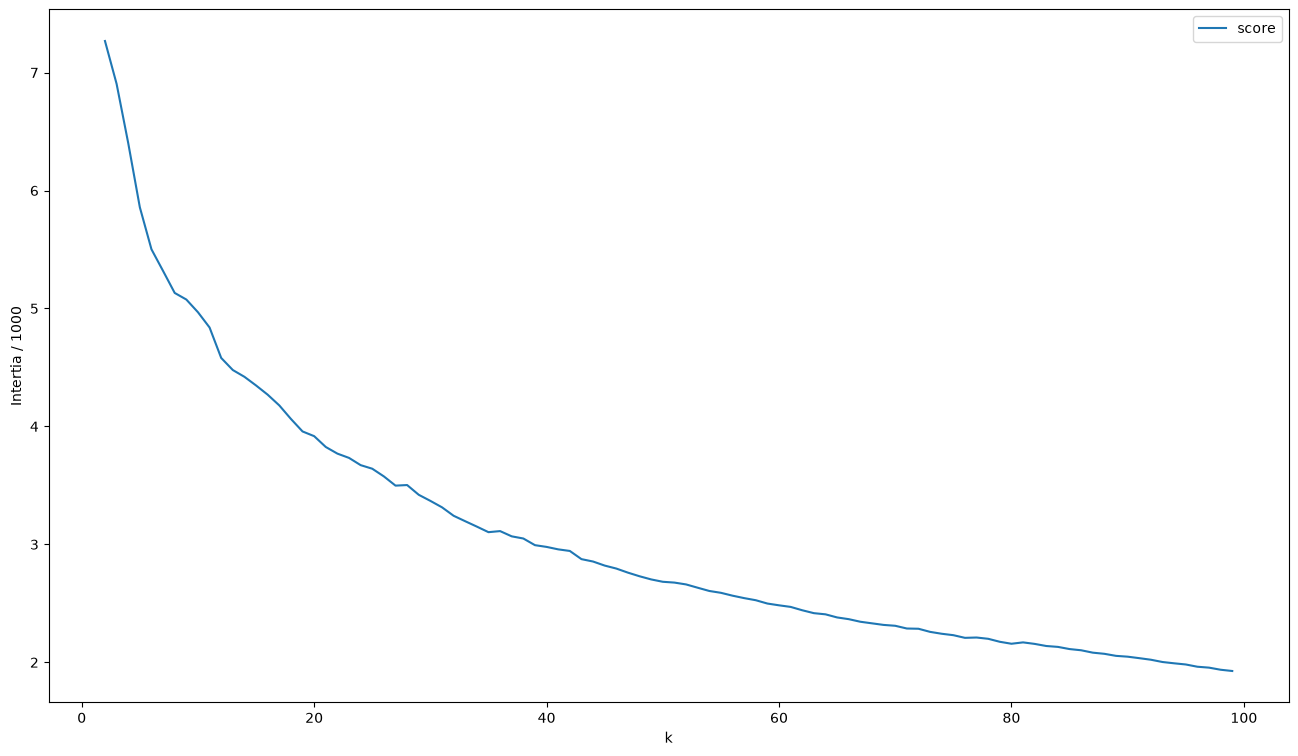

In [24]:
fig = plt.figure(figsize=(16,9))
axis = fig.add_subplot(1, 1, 1)
intertia_df.sort_values(by="k").plot("k", "score", ax=axis)

axis.set_ylabel("Intertia / 1000")
plt.show()

In [32]:
#Finding Best K value with elbow method 
k = 45
cluster_model = KMeans(n_clusters=k, random_state=42)
cluster_model.fit(df)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",45
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](45, 156)

In [33]:
#Make cluster using Kmeans/Edclidian 
cluster_labels = cluster_model.predict(df)
openings_cluster_df = pd.DataFrame(cluster_labels, index=df.index, columns=["clusters"])
openings_cluster_df["clusters"].value_counts()

clusters
0     130
7     109
9      85
14     75
23     73
6      67
29     58
30     57
18     57
20     53
44     53
12     52
21     49
22     48
11     48
38     44
1      44
27     40
19     40
24     39
25     35
39     35
15     34
13     34
10     33
41     33
36     31
2      30
17     30
35     30
8      29
37     29
32     28
43     27
5      26
3      25
16     25
28     24
33     23
31     22
34     22
40     18
26     14
4      13
42     13
Name: count, dtype: int64

In [34]:
for cluster, openings in openings_cluster_df.groupby("clusters"):
    print(f"cluster: {cluster}, size: {len(openings)}")
    for opening in openings.sample(5).index:
        print(opening)
    print()

cluster: 0, size: 130
King's Indian Defense, Orthodox Variation, Bayonet Attack
King's Indian Defense, Four Pawns Attack
King's Indian Defense, Steiner Attack
King's Indian Defense, Four Pawns Attack, General
King's Indian Defense, Averbakh Variation, Geller Defense

cluster: 1, size: 44
Reti Opening, Anglo-Slav Variation, New York System
Reti Opening, Anglo-Slav Variation, Bogoljubow Variation
English Opening, Agincourt Defense, Wimpy System
King's Indian Attack, Symmterical Defense
English Opening, Anglo-Indian Defense, Scandinavian Defense

cluster: 2, size: 30
Benko Gambit, Accepted, Fianchetto Variation
Benko Gambit, Declined, Pseudo-Saemisch
Benoni Defense, Modern Variation
Benko Gambit, Accepted, Dlugy Variation
Benko Gambit, Accepted, Yugoslav with 7...Bxf1, Nge2

cluster: 3, size: 25
French Defense, Tarrasch Variation, Guimard Defense, Main Line
French Defense, Tarrasch Variation, Guimard Defense
French Defense, Tarrasch Variation, Open System, Main Line
French Defense, Tarras